# 06 · E3 data-quality test and E1 scalability test

**E3 · Can our checks catch bad data?** We take a copy of the raw monthly data, break **450 cells on purpose in 9 different ways**, run the same rules as Silver, and count how many breaks are caught. Target from the proposal: **at least 90%**. We also run the rules on the clean data to prove they raise **no false alarms**.

**E1 · Does the pipeline scale?** Our real data is small (about 0.6 million rows), so timings would mostly measure Spark's start-up cost. So we also build a **40× scaled copy** (about 22 million rows) and time a typical Silver → Gold job:
- **Test 1, data size:** 25%, 50%, 75%, 100% of the data, all cores
- **Test 2, CPU cores:** 1, 2, 4, 8, 12 cores, full data → **speed-up** and **efficiency**

Results go to `IAIP\reports\` (CSV) and `IAIP\reports\figures\` (charts). **Allow 10–20 minutes**; Test 2 with 1 core is the slow part. Close other heavy programs while it runs, so the timings are fair.

## Step 1 · Start Spark

In [1]:
import os, sys, time, shutil, random
from pathlib import Path
from collections import Counter

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
from pyspark.sql import SparkSession, functions as F, Window

def start_spark(cores):
    return (SparkSession.builder.appName(f"IAIP-06-{cores}cores").master(f"local[{cores}]")
            .config("spark.driver.memory", "4g")            # only used when Java first starts
            .config("spark.sql.shuffle.partitions", "24")   # same for every test, so runs are comparable
            .config("spark.sql.ansi.enabled", "false")
            .getOrCreate())

MAX_CORES = os.cpu_count()
spark = start_spark(MAX_CORES)
spark.sparkContext.setLogLevel("ERROR")

BASE = Path.cwd().parent
WH = BASE / "warehouse"
REP, FIG = BASE / "reports", BASE / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
import matplotlib.pyplot as plt
print("Spark", spark.version, "| CPU cores on this laptop:", MAX_CORES)

c:\Users\Arka\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark 4.2.0 | CPU cores on this laptop: 12


# Part 1 · E3 data-quality test

## Step 2 · The quality rules (same as Silver)

| Rule | Looks at | Catches |
|---|---|---|
| known state | each cell | a state name VAHAN never uses |
| real month | each cell | a month label that is not a date |
| missing value | each cell | an empty cell |
| is a number | each cell | text such as `12O4` |
| not negative | each cell | `-250` |
| whole number | each cell | `120.5` registrations |
| no duplicates | each cell | the same cell twice |
| complete row / month | a state or a month in a file | a lost row, or a state with a month missing |
| **row total** / **month total** | a state or a month in a file | numbers that no longer add up to VAHAN's own *Total* |

The last two are the clever ones: VAHAN gives a Total row and a Total column in every file, so a number that was **quietly changed** (still a valid-looking number) breaks the totals. When both the row total and the month total fail, we know the exact cell.

In [2]:
def to_number(c):
    c = F.trim(F.regexp_replace(c, ",", ""))
    return F.when(c.isNull() | c.isin("", "NA", "-"), F.lit(None)).otherwise(c.cast("double"))

KEY = ["source_file", "row_label", "column_label"]
NAMES = (spark.read.parquet((WH / "silver" / "state_name_map").as_uri())
         .filter("source = 'VAHAN'").select(F.col("raw_name").alias("row_label")).distinct().cache())
clean = (spark.read.parquet((WH / "bronze" / "reg_state_month").as_uri())
         .select("source_file", "row_label", "column_label", "value_raw", "is_total", "vehicle_type", "fuel_group")
         .dropDuplicates(KEY + ["value_raw"]).cache())
EXPECTED_COLS = clean.groupBy("source_file").agg(F.countDistinct("column_label").alias("n_expected")).cache()
EXPECTED_ROWS = 37                                         # 36 states/UTs + the Total row

def run_checks(df):
    """Run every rule; return {rule: set of flagged keys}."""
    df = df.withColumn("v", to_number(F.col("value_raw"))).cache()
    cell = lambda d: {tuple(r) for r in d.select(*KEY).collect()}
    pair = lambda d, a, b: {tuple(r) for r in d.select(a, b).collect()}
    raw_blank = F.col("value_raw").isNull() | F.trim("value_raw").isin("", "NA", "-")
    f = {}
    f["unknown state"]  = cell(df.filter("row_label <> 'Total'").join(NAMES, "row_label", "left_anti"))
    f["bad month"]      = cell(df.filter("column_label <> 'Total'")
                                 .filter(F.to_date(F.concat("column_label", F.lit("-01")), "yyyy-MMM-dd").isNull()))
    f["missing value"]  = cell(df.filter(raw_blank))
    f["not a number"]   = cell(df.filter(~raw_blank & F.col("v").isNull()))
    f["negative"]       = cell(df.filter(F.col("v") < 0))
    f["not whole"]      = cell(df.filter(F.col("v") != F.floor("v")))
    f["duplicate"]      = cell(df.groupBy(*KEY).count().filter("count > 1"))
    rows = df.groupBy("source_file", "row_label").agg(F.countDistinct("column_label").alias("n")).join(EXPECTED_COLS, "source_file")
    f["incomplete row"] = pair(rows.filter("n <> n_expected"), "source_file", "row_label")
    months = df.groupBy("source_file", "column_label").agg(F.countDistinct("row_label").alias("n"))
    f["incomplete month"] = pair(months.filter(f"n <> {EXPECTED_ROWS}"), "source_file", "column_label")
    # month total: the states must add up to the Total row
    parts = df.filter("row_label <> 'Total'").groupBy("source_file", "column_label").agg(F.sum("v").alias("s"))
    tot   = df.filter("row_label = 'Total'").select("source_file", "column_label", F.col("v").alias("t"))
    f["month total"] = pair(parts.join(tot, ["source_file", "column_label"], "full")
                                 .filter(F.coalesce("s", F.lit(-1.0)) != F.coalesce("t", F.lit(-2.0))), "source_file", "column_label")
    # row total: the months must add up to the Total column
    parts = df.filter("column_label <> 'Total'").groupBy("source_file", "row_label").agg(F.sum("v").alias("s"))
    tot   = df.filter("column_label = 'Total'").select("source_file", "row_label", F.col("v").alias("t"))
    f["row total"] = pair(parts.join(tot, ["source_file", "row_label"], "full")
                               .filter(F.coalesce("s", F.lit(-1.0)) != F.coalesce("t", F.lit(-2.0))), "source_file", "row_label")
    df.unpersist()
    return f

t0 = time.time()
clean_flags = run_checks(clean)
false_alarms = sum(len(v) for v in clean_flags.values())
print(f"Clean data: {clean.count():,} cells checked in {time.time()-t0:.1f} s")
for rule, keys in clean_flags.items():
    print(f"  {rule:17} {len(keys)} flags")
print("FALSE ALARMS ON CLEAN DATA:", false_alarms, "(should be 0)")

Clean data: 44,030 cells checked in 6.5 s
  unknown state     0 flags
  bad month         0 flags
  missing value     0 flags
  not a number      0 flags
  negative          0 flags
  not whole         0 flags
  duplicate         0 flags
  incomplete row    0 flags
  incomplete month  0 flags
  month total       0 flags
  row total         0 flags
FALSE ALARMS ON CLEAN DATA: 0 (should be 0)


## Step 3 · Break the data on purpose (450 cells, 50 of each kind)

We pick 450 random cells (fixed random seed, so the test can be repeated exactly) and damage them:

| # | Kind of break | Example |
|---|---|---|
| 1 | unknown state | `Kerala` → `Kerala X` |
| 2 | bad month label | `2026-Jan` → `2026/Jan` |
| 3 | missing value | `1,234` → empty |
| 4 | text in number | `1,234` → `1,234O` (letter O) |
| 5 | negative value | `1,234` → `-1,234` |
| 6 | decimal value | `1,234` → `1234.5` |
| 7 | duplicate row | the same cell appears twice |
| 8 | **quietly changed value** | `1,234` → `1734` (still looks fine!) |
| 9 | **lost row** | the cell disappears |

Kinds 8 and 9 look perfectly normal on their own; only the totals and completeness rules can catch them.

In [3]:
TYPES = ["unknown state", "bad month label", "missing value", "text in number", "negative value",
         "decimal value", "duplicate row", "quietly changed value", "lost row"]
N_PER_TYPE = 50

picked = (clean.filter(~F.col("is_total") & (F.col("fuel_group") != "ALL"))
               .withColumn("v", to_number(F.col("value_raw"))).filter("v > 0")
               .withColumn("r", F.rand(231)).orderBy("r").limit(N_PER_TYPE * len(TYPES))
               .withColumn("err_type", F.element_at(F.array(*[F.lit(t) for t in TYPES]),
                                                   ((F.row_number().over(Window.orderBy("r")) - 1) % len(TYPES) + 1).cast("int")))
               .select(*KEY, "err_type").cache())
INJECTED = [r.asDict() for r in picked.collect()]

e = F.col("err_type")
broken = (clean.join(picked, KEY, "left")
    .withColumn("row_label", F.when(e == "unknown state", F.concat("row_label", F.lit(" X"))).otherwise(F.col("row_label")))
    .withColumn("column_label", F.when(e == "bad month label", F.regexp_replace("column_label", "-", "/")).otherwise(F.col("column_label")))
    .withColumn("value_raw",
        F.when(e == "missing value", F.lit(""))
         .when(e == "text in number", F.concat("value_raw", F.lit("O")))
         .when(e == "negative value", F.concat(F.lit("-"), "value_raw"))
         .when(e == "decimal value", F.concat(F.regexp_replace("value_raw", ",", ""), F.lit(".5")))
         .when(e == "quietly changed value", (to_number(F.col("value_raw")) + 500).cast("long").cast("string"))
         .otherwise(F.col("value_raw"))))
broken = (broken.filter(e.isNull() | (e != "lost row"))
                .unionByName(broken.filter(e == "duplicate row"))
                .drop("err_type"))
print(f"clean cells: {clean.count():,} | broken copy: {broken.count():,} | breaks injected: {len(INJECTED)}")
print(Counter(r["err_type"] for r in INJECTED))

clean cells: 44,030 | broken copy: 44,030 | breaks injected: 450
Counter({'unknown state': 50, 'bad month label': 50, 'missing value': 50, 'text in number': 50, 'negative value': 50, 'decimal value': 50, 'duplicate row': 50, 'quietly changed value': 50, 'lost row': 50})


## Step 4 · Run the rules on the broken copy and score them

A break counts as **caught** if any rule flags its cell, its state row or its month. We also record **where** it was located:
- **exact cell**: a cell rule fired, or both the row total and the month total point to it
- **row or month only**: we know which state (or which month) is wrong, but not the exact cell

In [4]:
t0 = time.time()
flags = run_checks(broken)
print(f"rules ran on the broken copy in {time.time()-t0:.1f} s")
CELL_RULES = ["unknown state", "bad month", "missing value", "not a number", "negative", "not whole", "duplicate"]
ROW_RULES, MONTH_RULES = ["incomplete row", "row total"], ["incomplete month", "month total"]

def new_key(r):
    row = r["row_label"] + " X" if r["err_type"] == "unknown state" else r["row_label"]
    col = r["column_label"].replace("-", "/") if r["err_type"] == "bad month label" else r["column_label"]
    return r["source_file"], row, col

results = []
for r in INJECTED:
    f, row, col = new_key(r)
    rows_ = {(f, row), (f, r["row_label"])}
    cols_ = {(f, col), (f, r["column_label"])}
    hit_cell  = [x for x in CELL_RULES if (f, row, col) in flags[x]]
    hit_row   = [x for x in ROW_RULES if rows_ & flags[x]]
    hit_month = [x for x in MONTH_RULES if cols_ & flags[x]]
    caught_by = hit_cell + hit_row + hit_month
    where = ("exact cell" if hit_cell or (hit_row and hit_month) else
             "row or month only" if caught_by else "NOT CAUGHT")
    results.append((r["err_type"], bool(caught_by), where, ", ".join(caught_by)))

res = spark.createDataFrame(results, "err_type string, caught boolean, located string, caught_by string")
summary = (res.groupBy("err_type")
              .agg(F.count("*").alias("injected"), F.sum(F.col("caught").cast("int")).alias("caught"),
                   F.sum((F.col("located") == "exact cell").cast("int")).alias("exact_cell"),
                   F.first("caught_by").alias("example_rules_that_fired"))
              .withColumn("caught_pct", F.round(100 * F.col("caught") / F.col("injected"), 1))
              .orderBy(F.array_position(F.array(*[F.lit(t) for t in TYPES]), F.col("err_type"))))
summary.select("err_type", "injected", "caught", "caught_pct", "exact_cell", "example_rules_that_fired").show(truncate=False)

total_caught = sum(r[1] for r in results)
print(f"E3 RESULT: {total_caught} of {len(results)} breaks caught = {100*total_caught/len(results):.1f}%  (target >= 90%)")
print(f"located to the exact cell: {sum(r[2] == 'exact cell' for r in results)} of {len(results)}")
print(f"false alarms on the clean data: {false_alarms}")
print("(Streaming path, notebook 04 Demo C: 50 of 50 broken Kafka messages caught.)")

REP.mkdir(exist_ok=True)
SUMMARY_PD = summary.toPandas()          # keep a copy: Spark restarts in Part 2
SUMMARY_PD.to_csv(REP / "e3_quality_test.csv", index=False)

rules ran on the broken copy in 4.1 s
+---------------------+--------+------+----------+----------+-------------------------------------------------------------------+
|err_type             |injected|caught|caught_pct|exact_cell|example_rules_that_fired                                           |
+---------------------+--------+------+----------+----------+-------------------------------------------------------------------+
|unknown state        |50      |50    |100.0     |50        |unknown state, incomplete row, row total                           |
|bad month label      |50      |50    |100.0     |50        |bad month, incomplete row, row total, incomplete month, month total|
|missing value        |50      |50    |100.0     |50        |missing value, row total, month total                              |
|text in number       |50      |50    |100.0     |50        |not a number, row total, month total                               |
|negative value       |50      |50    |100.0     |50

c:\Users\Arka\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


# Part 2 · E1 scalability test

## Step 5 · Build the 40× scaled copy

Each row of the raw maker and monthly tables is repeated 40 times, with a column `rep` = 0 … 39. The copy is saved **partitioned by `rep`**, so "25% of the data" simply means reading folders `rep` 0–9. Every run reads the same files the same way.

In [5]:
SCALE = 40
SCALED = WH / "_scale_test"
reps = spark.range(SCALE).withColumnRenamed("id", "rep")
for name in ["reg_maker_state_year", "reg_state_month"]:
    out = SCALED / name
    if not out.exists():
        t0 = time.time()
        (spark.read.parquet((WH / "bronze" / name).as_uri()).crossJoin(F.broadcast(reps))
              .repartition(SCALE, "rep").write.mode("overwrite").partitionBy("rep").parquet(out.as_uri()))
        print(f"built {name} x{SCALE} in {time.time()-t0:.0f} s")
for name in ["reg_maker_state_year", "reg_state_month"]:
    print(f"{name:22} real {spark.read.parquet((WH/'bronze'/name).as_uri()).count():>10,} rows"
          f" | scaled {spark.read.parquet((SCALED/name).as_uri()).count():>12,} rows")

built reg_maker_state_year x40 in 10 s
built reg_state_month x40 in 2 s
reg_maker_state_year   real    546,527 rows | scaled   21,861,080 rows
reg_state_month        real     44,030 rows | scaled    1,761,200 rows


## Step 6 · The test job (a typical Silver → Gold workload)

1. **Maker data:** clean the numbers, map maker names to brands with regular expressions (the CPU-heavy step), add up by brand × state × year, rank brands (window function).
2. **Monthly data:** turn labels into dates, add up EV and total registrations by state × month × type, compute EV share.

The result is written to Spark's `noop` sink: Spark does all the work but throws the result away, so disk speed does not distort the timing.

In [6]:
BRANDS = [("Hero MotoCorp", r"^HERO "), ("Honda", r"HONDA"), ("TVS Motor", r"^TVS "), ("Bajaj Auto", r"^BAJAJ"),
          ("Maruti Suzuki", r"^MARUTI"), ("Mahindra", r"^MAHINDRA(?! & ASSOCIATES)"), ("Tata Motors", r"^TATA (MOTORS|PASSENGER)"),
          ("Royal Enfield", r"ROYAL ENFIELD|^EICHER"), ("Hyundai", r"^HYUNDAI"), ("Ola Electric", r"^OLA ELECTRIC"),
          ("Suzuki Motorcycle", r"^SUZUKI MOTORCYCLE"), ("Toyota", r"^TOYOTA"), ("Ashok Leyland", r"^ASHOK LEYLAND"),
          ("Escorts Kubota", r"^ESCORTS|^KUBOTA"), ("Ather", r"^ATHER")]

def brand_of(c):
    out = F.lit("Long tail")
    for name, pattern in reversed(BRANDS):
        out = F.when(c.rlike(pattern), name).otherwise(out)
    return out

def workload(sp, fraction):
    n_reps = max(1, round(SCALE * fraction))
    mk = sp.read.parquet((SCALED / "reg_maker_state_year").as_uri()).filter(F.col("rep") < n_reps)
    sm = sp.read.parquet((SCALED / "reg_state_month").as_uri()).filter(F.col("rep") < n_reps)
    brand = (mk.filter(~F.col("is_total"))
               .withColumn("v", to_number(F.col("value_raw")))
               .withColumn("year", F.regexp_extract("source_file", r"(\d{4})", 1))
               .withColumn("brand", brand_of(F.upper(F.trim(F.regexp_replace("row_label", r"\s+", " ")))))
               .groupBy("brand", "column_label", "year", "vehicle_type").agg(F.sum("v").alias("reg"))
               .withColumn("rank", F.rank().over(Window.partitionBy("column_label", "year", "vehicle_type").orderBy(F.desc("reg")))))
    ev = (sm.filter(~F.col("is_total") & (F.col("fuel_group") != "ALL"))
            .withColumn("month_date", F.to_date(F.concat("column_label", F.lit("-01")), "yyyy-MMM-dd"))
            .withColumn("v", to_number(F.col("value_raw")))
            .groupBy("row_label", "month_date", "vehicle_type")
            .agg((100 * F.sum(F.when(F.col("fuel_group") == "EV", F.col("v")).otherwise(0)) / F.sum("v")).alias("ev_share")))
    t0 = time.time()
    brand.write.format("noop").mode("overwrite").save()
    ev.write.format("noop").mode("overwrite").save()
    return time.time() - t0, n_reps

def timed(sp, fraction, repeats=2):
    """Run the job `repeats` times and keep the fastest (the first run also warms up Java)."""
    return min(workload(sp, fraction)[0] for _ in range(repeats))

ROWS_FULL = (spark.read.parquet((SCALED / "reg_maker_state_year").as_uri()).count()
             + spark.read.parquet((SCALED / "reg_state_month").as_uri()).count())
workload(spark, 0.25)                      # warm-up, not timed
print(f"full scaled input: {ROWS_FULL:,} rows")

full scaled input: 23,622,280 rows


## Step 7 · Test 1: data size (25 → 100%), all cores

If the pipeline scales well, **double the data ≈ double the time** (a straight line), not worse.

In [7]:
E1 = []
real_s = min(workload(spark, 1 / SCALE)[0] for _ in range(2))
E1.append(("real data (1x)", MAX_CORES, 1 / SCALE, ROWS_FULL // SCALE, round(real_s, 2)))
print(f"real data, 1x ({ROWS_FULL//SCALE:,} rows): {real_s:.1f} s")
for frac in [0.25, 0.50, 0.75, 1.00]:
    s = timed(spark, frac)
    E1.append(("data size", MAX_CORES, frac, int(ROWS_FULL * frac), round(s, 2)))
    print(f"{int(frac*100):>3}% of scaled data ({int(ROWS_FULL*frac):>11,} rows), {MAX_CORES} cores: {s:6.1f} s")

real data, 1x (590,557 rows): 4.2 s
 25% of scaled data (  5,905,570 rows), 12 cores:    8.0 s
 50% of scaled data ( 11,811,140 rows), 12 cores:   15.3 s
 75% of scaled data ( 17,716,710 rows), 12 cores:   23.3 s
100% of scaled data ( 23,622,280 rows), 12 cores:   30.4 s


## Step 8 · Test 2: CPU cores (1 → all), full scaled data

Spark is restarted with `local[n]` for each core count.
- **Speed-up** = time with 1 core ÷ time with *n* cores (ideal = *n*)
- **Efficiency** = speed-up ÷ *n* (ideal = 100%). It always drops a little, because some work cannot be split (start-up, the final ranking, the shuffle between steps), and because a laptop's cores share memory and slow down when hot.

In [8]:
CORES = sorted({c for c in [1, 2, 4, 8, MAX_CORES] if c <= MAX_CORES})
for n in CORES:
    spark.stop()
    spark = start_spark(n)
    spark.sparkContext.setLogLevel("ERROR")
    workload(spark, 0.25)                                  # warm-up for this core count
    s = timed(spark, 1.0)
    E1.append(("cores", n, 1.0, ROWS_FULL, round(s, 2)))
    print(f"{n:>2} cores: {s:6.1f} s")

e1 = spark.createDataFrame(E1, "test string, cores int, fraction double, rows long, seconds double")
t1 = e1.filter("test = 'cores' AND cores = 1").first()["seconds"]
e1 = (e1.withColumn("speedup", F.when(F.col("test") == "cores", F.round(F.lit(t1) / F.col("seconds"), 2)))
        .withColumn("efficiency_pct", F.when(F.col("test") == "cores", F.round(100 * F.lit(t1) / F.col("seconds") / F.col("cores"), 1)))
        .withColumn("rows_per_sec", F.round(F.col("rows") / F.col("seconds"))))
e1.show(truncate=False)
E1PD = e1.toPandas()
E1PD.to_csv(REP / "e1_scalability.csv", index=False)

 1 cores:  156.9 s
 2 cores:   83.3 s
 4 cores:   45.0 s
 8 cores:   32.1 s
12 cores:   32.4 s
+--------------+-----+--------+--------+-------+-------+--------------+------------+
|test          |cores|fraction|rows    |seconds|speedup|efficiency_pct|rows_per_sec|
+--------------+-----+--------+--------+-------+-------+--------------+------------+
|real data (1x)|12   |0.025   |590557  |4.15   |NULL   |NULL          |142303.0    |
|data size     |12   |0.25    |5905570 |7.99   |NULL   |NULL          |739120.0    |
|data size     |12   |0.5     |11811140|15.33  |NULL   |NULL          |770459.0    |
|data size     |12   |0.75    |17716710|23.31  |NULL   |NULL          |760048.0    |
|data size     |12   |1.0     |23622280|30.41  |NULL   |NULL          |776793.0    |
|cores         |1    |1.0     |23622280|156.85 |1.0    |100.0         |150604.0    |
|cores         |2    |1.0     |23622280|83.34  |1.88   |94.1          |283445.0    |
|cores         |4    |1.0     |23622280|45.01  |3.48   

c:\Users\Arka\AppData\Local\Programs\Python\Python311\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


## Step 9 · Charts for the report

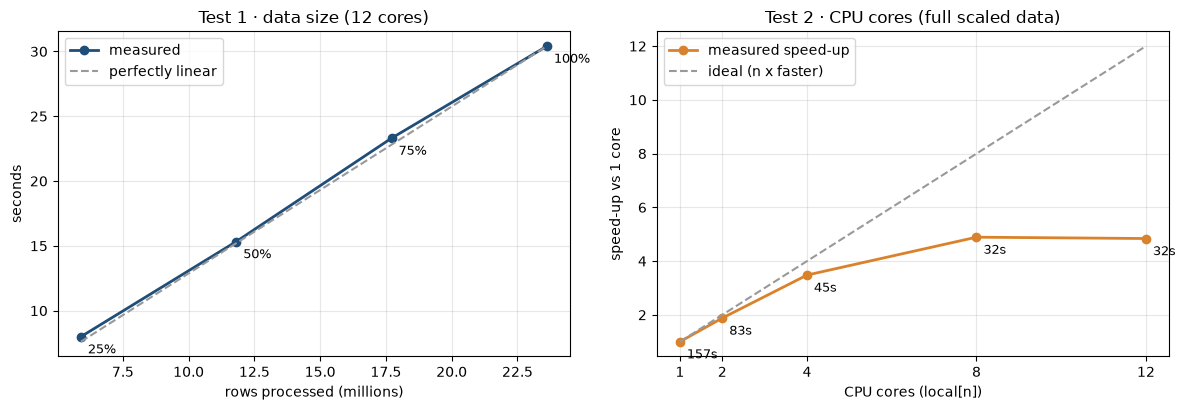

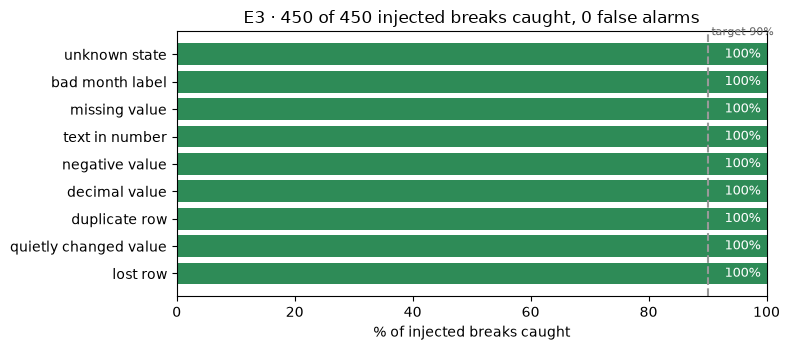

In [9]:
size = E1PD[E1PD.test == "data size"]
cores = E1PD[E1PD.test == "cores"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(size.rows / 1e6, size.seconds, marker="o", color="#1f4e79", lw=2, label="measured")
k = size.seconds.iloc[-1] / size.rows.iloc[-1]
ax.plot(size.rows / 1e6, size.rows * k, ls="--", color="#999999", label="perfectly linear")
for _, r in size.iterrows():
    ax.annotate(f"{int(r.fraction*100)}%", (r.rows / 1e6, r.seconds), xytext=(5, -12), textcoords="offset points", fontsize=9)
ax.set_xlabel("rows processed (millions)"); ax.set_ylabel("seconds"); ax.set_title(f"Test 1 · data size ({MAX_CORES} cores)")
ax.grid(alpha=.3); ax.legend()

ax = axes[1]
ax.plot(cores.cores, cores.speedup, marker="o", color="#d9822b", lw=2, label="measured speed-up")
ax.plot(cores.cores, cores.cores, ls="--", color="#999999", label="ideal (n x faster)")
for _, r in cores.iterrows():
    ax.annotate(f"{r.seconds:.0f}s", (r.cores, r.speedup), xytext=(5, -12), textcoords="offset points", fontsize=9)
ax.set_xlabel("CPU cores (local[n])"); ax.set_ylabel("speed-up vs 1 core"); ax.set_title("Test 2 · CPU cores (full scaled data)")
ax.set_xticks(cores.cores); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "e1_scalability.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))
s = SUMMARY_PD
ax.barh(s.err_type, s.caught_pct, color=["#2e8b57" if v >= 90 else "#c0392b" for v in s.caught_pct])
ax.axvline(90, ls="--", color="#999999"); ax.text(90, -0.7, " target 90%", color="#666666", fontsize=8)
for y, v in enumerate(s.caught_pct):
    ax.text(min(v, 100) - 1, y, f"{v:.0f}%", va="center", ha="right", color="white", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% of injected breaks caught")
ax.set_title(f"E3 · {total_caught} of {len(results)} injected breaks caught, 0 false alarms" if false_alarms == 0
             else f"E3 · {total_caught} of {len(results)} injected breaks caught")
plt.tight_layout(); plt.savefig(FIG / "e3_quality_test.png", dpi=150); plt.show()

## Step 10 · Summary and clean-up

The scaled copy takes a few hundred MB. Set `KEEP_SCALED_COPY = True` if you want to re-run Part 2 later without rebuilding it.

In [10]:
size_row = lambda f: E1PD[(E1PD.test == "data size") & (E1PD.fraction == f)].seconds.iloc[0]
best = cores.loc[cores.seconds.idxmin()]
print(f"E3: {100*total_caught/len(results):.1f}% of {len(results)} injected breaks caught (target 90%), {false_alarms} false alarms")
print(f"E1 data size: 25% -> {size_row(0.25):.1f} s, 100% -> {size_row(1.0):.1f} s  "
      f"(4x the data took {size_row(1.0)/size_row(0.25):.1f}x the time)")
print(f"E1 cores: 1 core {t1:.1f} s -> {int(best.cores)} cores {best.seconds:.1f} s  "
      f"(speed-up {best.speedup:.1f}x, efficiency {best.efficiency_pct:.0f}%)")

KEEP_SCALED_COPY = False
spark.stop()
if not KEEP_SCALED_COPY:
    shutil.rmtree(SCALED, ignore_errors=True)
    print("scaled copy deleted")

E3: 100.0% of 450 injected breaks caught (target 90%), 0 false alarms
E1 data size: 25% -> 8.0 s, 100% -> 30.4 s  (4x the data took 3.8x the time)
E1 cores: 1 core 156.8 s -> 8 cores 32.1 s  (speed-up 4.9x, efficiency 61%)
scaled copy deleted
